## Notebook to analyse the results robot drive experiments


5 drives with different parameters
- drive 1: `D25.0` PWM motor speed
- drive 2: `D50.0` PWM motor speed
- drive 3: `D75.0` PWM motor speed
- drive 4: `D100.0` PWM motor speed

- drive 5: `d25.0` and `d-25.0` PWM motor speed (opposite direction, on spot turn, not main experiment)

files in
```
RTP-T3-SoSe2026\02_Preperations\recorded-data\Log_30.04.2026_09.03.30-25per.txt
RTP-T3-SoSe2026\02_Preperations\recorded-data\Log_30.04.2026_09.06.16-50per.txt
RTP-T3-SoSe2026\02_Preperations\recorded-data\Log_30.04.2026_09.09.11-75per.txt
RTP-T3-SoSe2026\02_Preperations\recorded-data\Log_30.04.2026_09.14.01-100per.txt
RTP-T3-SoSe2026\02_Preperations\recorded-data\Log_30.04.2026_09.15.49-pm25per.txt
```



In [57]:
import pathlib as pl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = pl.Path("recorded-data")

paths = {
    "D25":   DATA_DIR / "Log_30.04.2026_09.03.30-25per.txt",
    "D50":   DATA_DIR / "Log_30.04.2026_09.06.16-50per.txt",
    "D75":   DATA_DIR / "Log_30.04.2026_09.09.11-75per.txt",
    "D100":  DATA_DIR / "Log_30.04.2026_09.14.01-100per.txt",
    "pmD25": DATA_DIR / "Log_30.04.2026_09.15.49-pm25per.txt",
}

FSAMPLE_HZ = 500  # from the `fsample=500Hz` header line


def load_log(path: pl.Path) -> pd.DataFrame:
    """Read a Serial.ICE log file (semicolon-separated, first line `fsample=...`)."""
    df = pd.read_csv(path, sep=";", skiprows=1, skipinitialspace=True)
    df.columns = [c.strip() for c in df.columns]
    df["t/s"] = df["Time/ms"] / 1000.0
    return df


def plot_raw(df: pd.DataFrame, title: str):
    """Four-panel raw-data plot: QEI1, QEI2, distance, motor PWM vs time."""
    fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
    axes[0].plot(df["t/s"], df["QEI1/steps"], color="tab:blue")
    axes[0].set_ylabel("QEI1 / steps")
    axes[1].plot(df["t/s"], df["QEI2/steps"], color="tab:orange")
    axes[1].set_ylabel("QEI2 / steps")
    axes[2].plot(df["t/s"], df["d/cm"], color="tab:green")
    axes[2].set_ylabel("distance / cm")
    mot_cols = [c for c in df.columns if c.startswith("Mot")]
    for col in mot_cols:
        axes[3].plot(df["t/s"], df[col], label=col)
    axes[3].set_ylabel("PWM / %")
    axes[3].set_xlabel("time / s")
    if len(mot_cols) > 1:
        axes[3].legend(loc="best")
    for ax in axes:
        ax.grid(True, alpha=0.3)
    fig.suptitle(title)
    fig.tight_layout()
    return fig, axes


def plot_motor_compare(df: pd.DataFrame, title: str):
    """Per-drive comparison: QEI1 and QEI2 overlaid, with their difference below."""
    fig, axes = plt.subplots(
        2, 1, figsize=(10, 6), sharex=True,
        gridspec_kw={"height_ratios": [3, 1]},
    )
    axes[0].plot(df["t/s"], df["QEI1/steps"], label="motor 0 (QEI1)", color="tab:blue")
    axes[0].plot(df["t/s"], df["QEI2/steps"], label="motor 1 (QEI2)", color="tab:orange")
    axes[0].set_ylabel("QEI position / steps")
    axes[0].legend(loc="lower right")
    axes[0].set_title(title)

    diff = df["QEI2/steps"] - df["QEI1/steps"]
    axes[1].plot(df["t/s"], diff, color="tab:red")
    axes[1].axhline(0, color="black", linewidth=0.5)
    axes[1].set_ylabel("QEI2 - QEI1\n/ steps")
    axes[1].set_xlabel("time / s")

    for ax in axes:
        ax.grid(True, alpha=0.3)
    fig.tight_layout()
    return fig, axes


def print_first_step_delay(df: pd.DataFrame, label: str = "") -> None:
    """Latency between the first non-zero motor command and the first QEI step.

    For each Mot* column, find when it first goes non-zero (= the moment the
    constant-PWM step is applied), then report when QEI1 and QEI2 each register
    their first count.
    """
    mot_cols = [c for c in df.columns if c.startswith("Mot")]
    head = f"[{label}] " if label else ""
    if not mot_cols:
        print(f"{head}no Mot* column in log")
        return
    mot = df[mot_cols[0]]
    nonzero = mot.values != 0
    if not nonzero.any():
        print(f"{head}{mot_cols[0]} stays 0 for the whole log")
        return
    cmd_pos = int(nonzero.argmax())
    t_cmd = float(df["Time/ms"].iloc[cmd_pos])
    val_cmd = float(mot.iloc[cmd_pos])
    print(f"{head}{mot_cols[0]} first reaches {val_cmd:g} % at t = {t_cmd:.0f} ms")
    for qei in ("QEI1/steps", "QEI2/steps"):
        if qei not in df.columns:
            continue
        qs = df[qei].values != 0
        if not qs.any():
            print(f"  {qei}: no step recorded")
            continue
        t_first = float(df["Time/ms"].iloc[int(qs.argmax())])
        print(f"  {qei}: first step at t = {t_first:.0f} ms  (Δt = {t_first - t_cmd:+.0f} ms)")


def angular_velocity(qei: pd.Series, t_s: pd.Series, smooth_window: int = 11) -> pd.Series:
    """Angular velocity in steps/s.

    Pre-smooths the integer-quantised position with a centered moving average
    of `smooth_window` samples (default 11 → 22 ms at 500 Hz), then takes a
    centered finite difference w.r.t. time using ``np.gradient``.
    """
    smoothed = qei.rolling(window=smooth_window, center=True, min_periods=1).mean()
    return pd.Series(np.gradient(smoothed.values, t_s.values), index=t_s.index)


def plot_velocity(df: pd.DataFrame, title: str, smooth_window: int = 11):
    """Both motors' angular velocity overlaid in one plot."""
    omega1 = angular_velocity(df["QEI1/steps"], df["t/s"], smooth_window)
    omega2 = angular_velocity(df["QEI2/steps"], df["t/s"], smooth_window)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(df["t/s"], omega1, label="motor 0 (dQEI1/dt)", color="tab:blue")
    ax.plot(df["t/s"], omega2, label="motor 1 (dQEI2/dt)", color="tab:orange")
    ax.set_xlabel("time / s")
    ax.set_ylabel(r"angular velocity / steps$\cdot$s$^{-1}$")
    ax.set_title(title)
    ax.legend(loc="best")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    return fig, ax

### Plot of raw data per file 



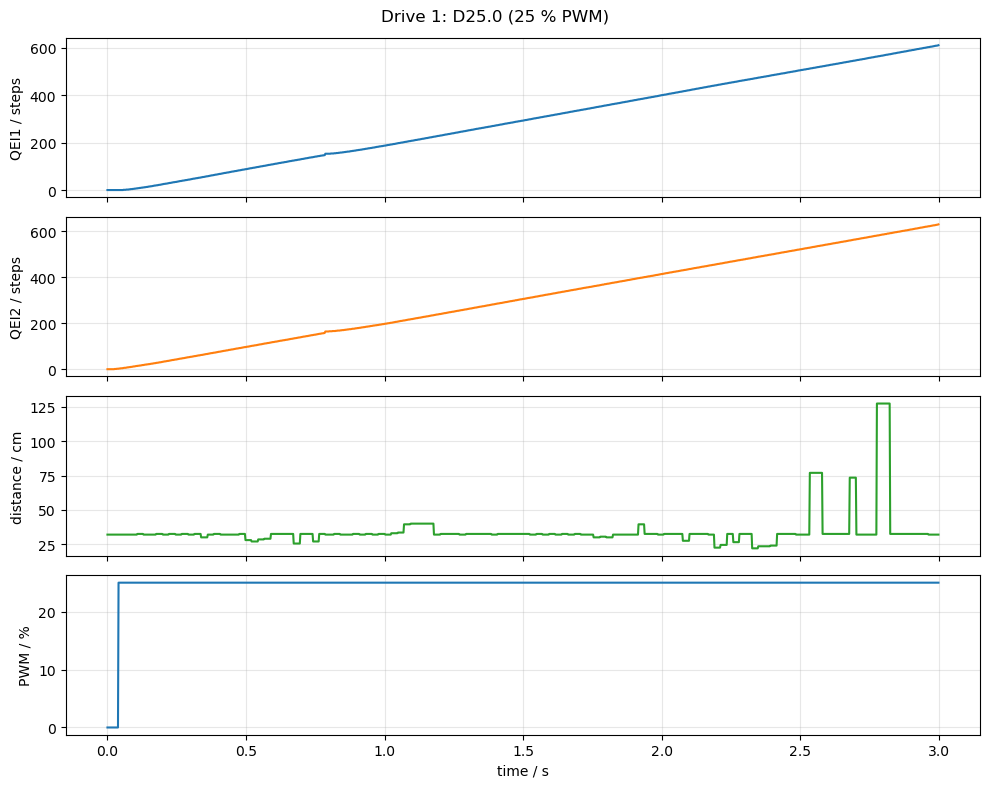

In [58]:
df_d25 = load_log(paths["D25"])
plot_raw(df_d25, "Drive 1: D25.0 (25 % PWM)")
plt.show()

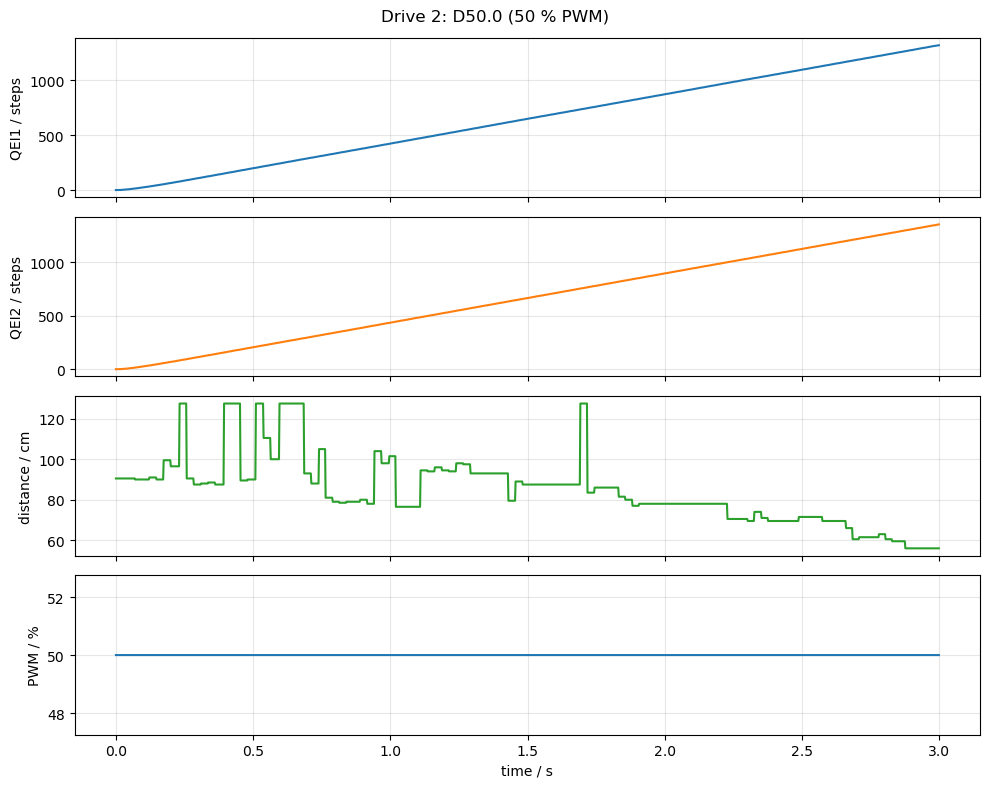

In [59]:
df_d50 = load_log(paths["D50"])
plot_raw(df_d50, "Drive 2: D50.0 (50 % PWM)")
plt.show()

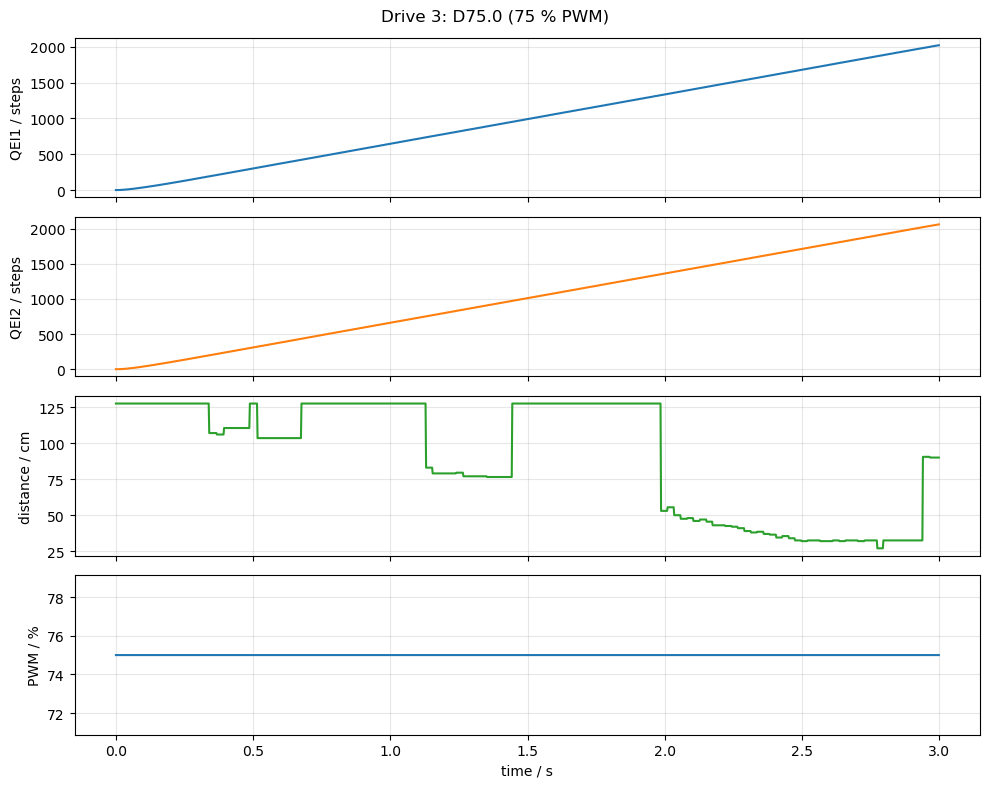

In [60]:
df_d75 = load_log(paths["D75"])
plot_raw(df_d75, "Drive 3: D75.0 (75 % PWM)")
plt.show()

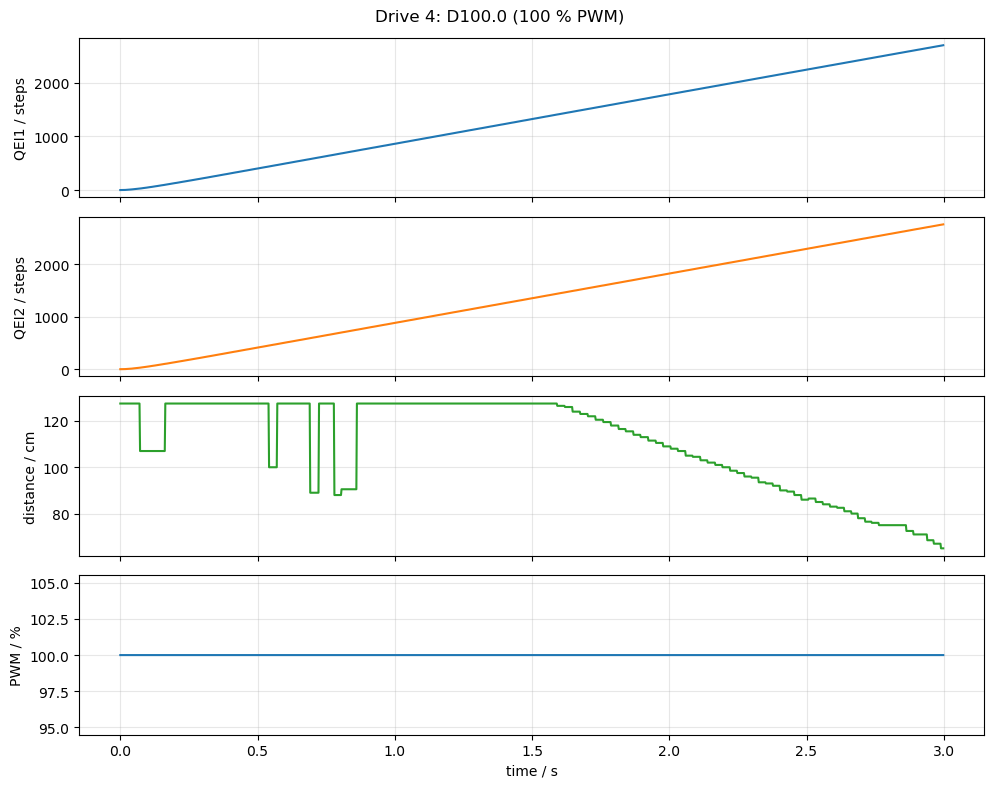

In [61]:
df_d100 = load_log(paths["D100"])
plot_raw(df_d100, "Drive 4: D100.0 (100 % PWM)")
plt.show()

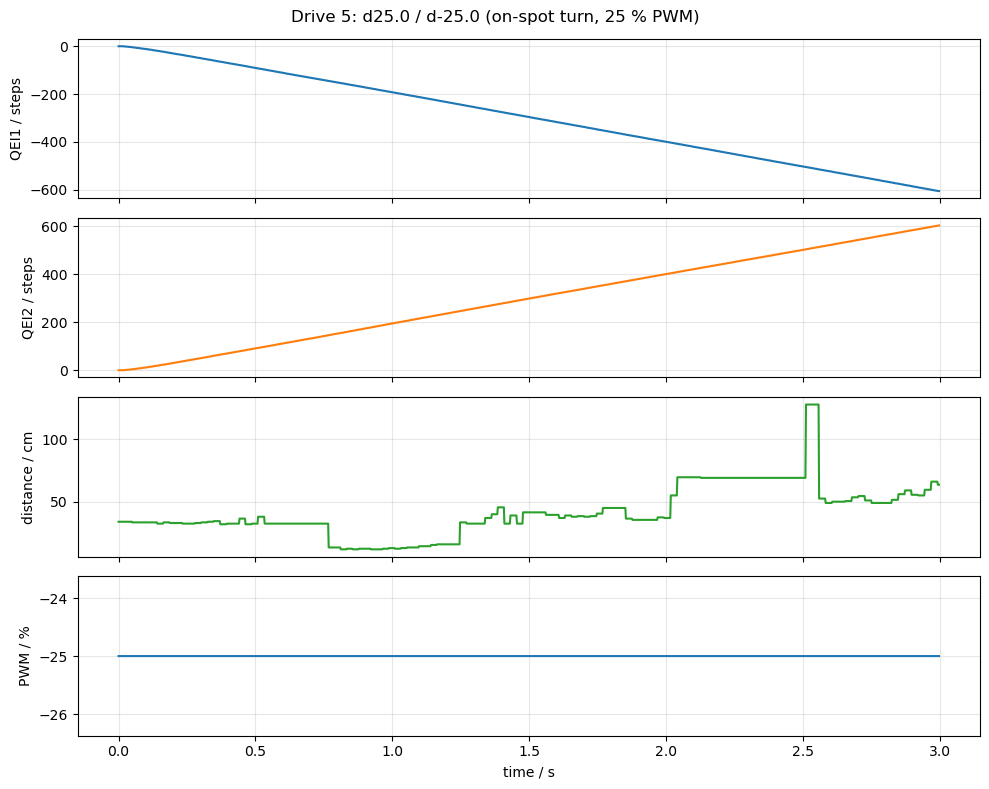

In [62]:
df_pmd25 = load_log(paths["pmD25"])
plot_raw(df_pmd25, "Drive 5: d25.0 / d-25.0 (on-spot turn, 25 % PWM)")
plt.show()

### Motor position QEI: motor 0 vs motor 1, per drive

For each of the four main drives the QEI step counts of motor 0 (`QEI1`) and
motor 1 (`QEI2`) are plotted on the same time axis (top panel) together with
their pointwise difference `QEI2 - QEI1` (bottom panel). The difference makes
the asymmetry between the two drive trains directly visible.

[D25] Mot0/% first reaches 25 % at t = 40 ms
  QEI1/steps: first step at t = 58 ms  (Δt = +18 ms)
  QEI2/steps: first step at t = 26 ms  (Δt = -14 ms)


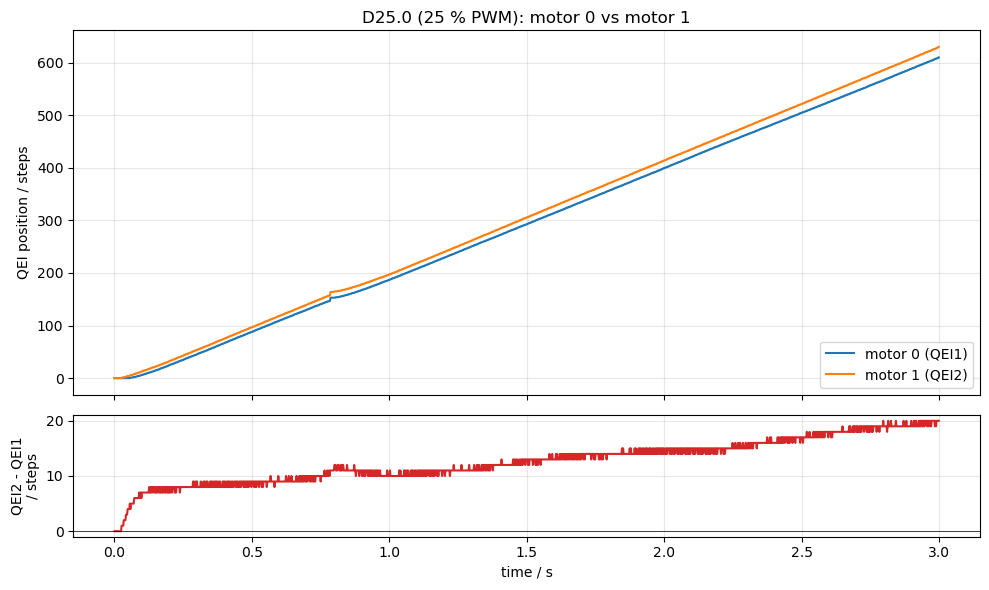

In [63]:
dfs = {key: load_log(paths[key]) for key in ("D25", "D50", "D75", "D100")}

print_first_step_delay(dfs["D25"], "D25")
plot_motor_compare(dfs["D25"], "D25.0 (25 % PWM): motor 0 vs motor 1")
plt.show()

[D50] Mot0/% first reaches 50 % at t = 0 ms
  QEI1/steps: first step at t = 14 ms  (Δt = +14 ms)
  QEI2/steps: first step at t = 14 ms  (Δt = +14 ms)


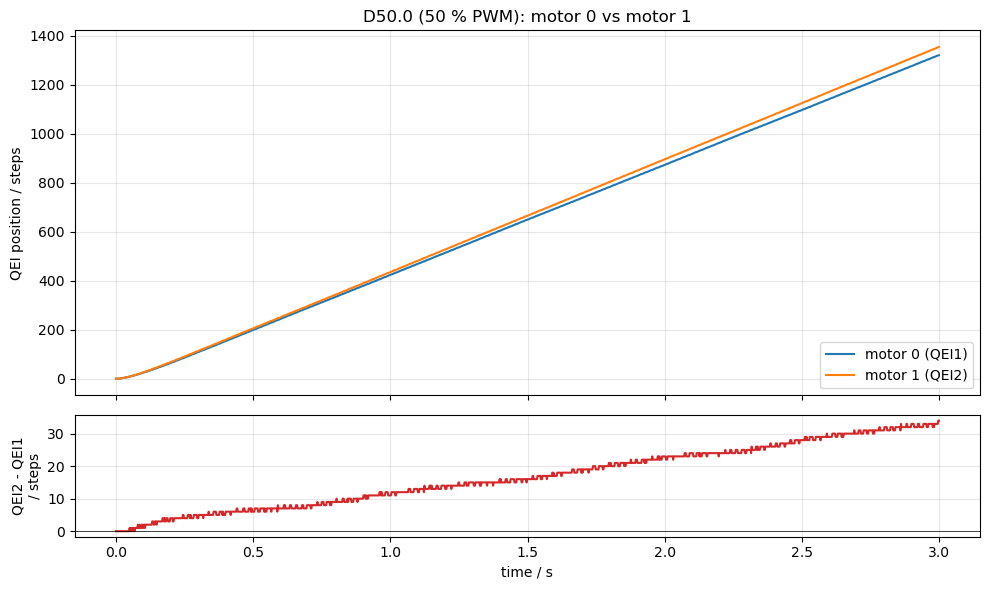

In [64]:
print_first_step_delay(dfs["D50"], "D50")
plot_motor_compare(dfs["D50"], "D50.0 (50 % PWM): motor 0 vs motor 1")
plt.show()

[D75] Mot0/% first reaches 75 % at t = 0 ms
  QEI1/steps: first step at t = 12 ms  (Δt = +12 ms)
  QEI2/steps: first step at t = 14 ms  (Δt = +14 ms)


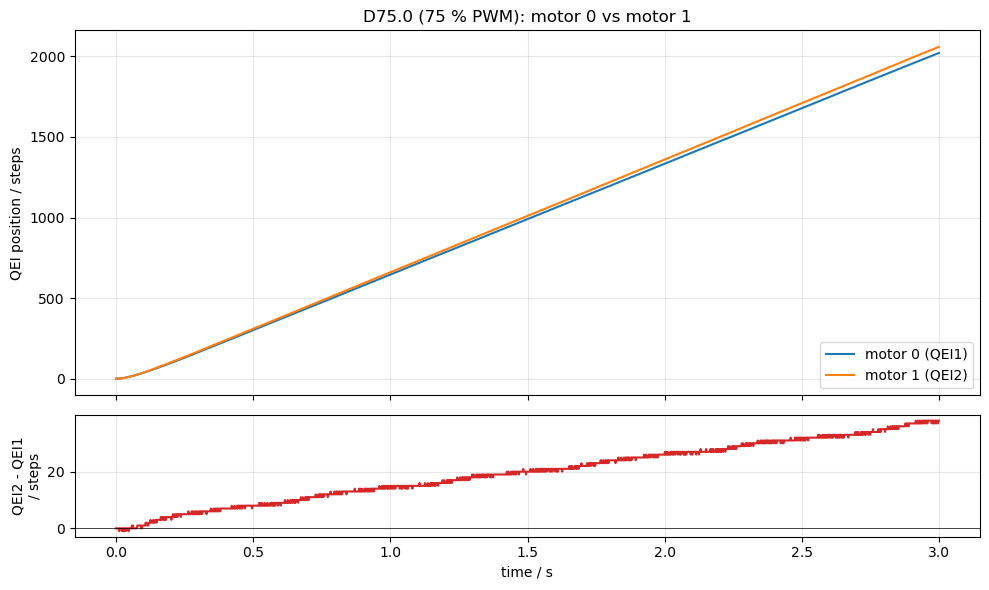

In [65]:
print_first_step_delay(dfs["D75"], "D75")
plot_motor_compare(dfs["D75"], "D75.0 (75 % PWM): motor 0 vs motor 1")
plt.show()

[D100] Mot0/% first reaches 100 % at t = 0 ms
  QEI1/steps: first step at t = 10 ms  (Δt = +10 ms)
  QEI2/steps: first step at t = 12 ms  (Δt = +12 ms)


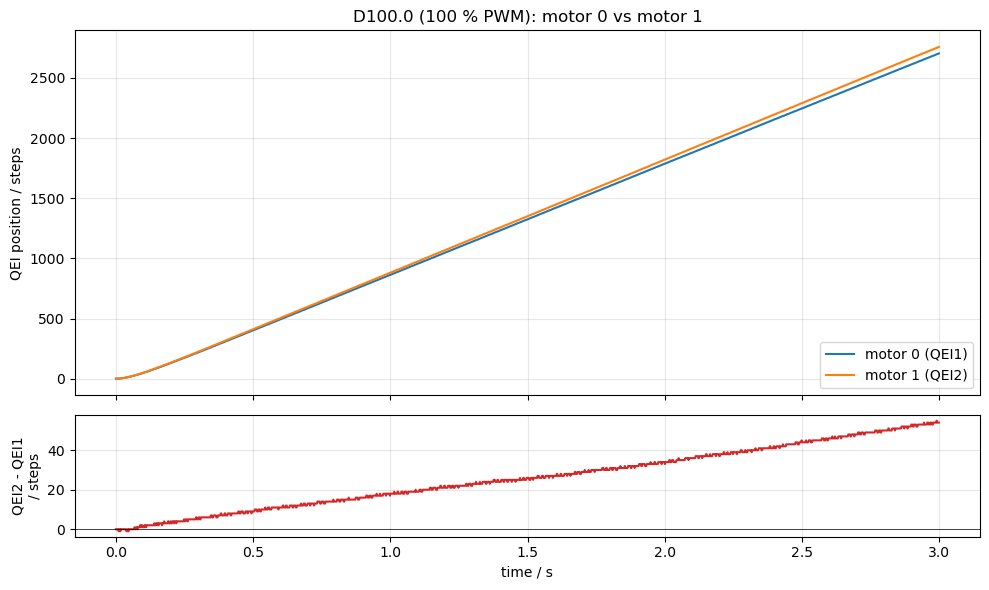

In [66]:
print_first_step_delay(dfs["D100"], "D100")
plot_motor_compare(dfs["D100"], "D100.0 (100 % PWM): motor 0 vs motor 1")
plt.show()

### Angular velocity (first derivative of QEI position)

For each main drive condition the angular velocities of motor 0 (`dQEI1/dt`)
and motor 1 (`dQEI2/dt`) are plotted in a single figure. The position signal
is pre-smoothed with a centered 11-sample (≈22 ms) moving average to suppress
the integer quantization, then differentiated by ``np.gradient``. Units are
QEI counts per second (steps/s); conversion to rad/s requires the encoder's
counts-per-revolution which is not part of the recording.

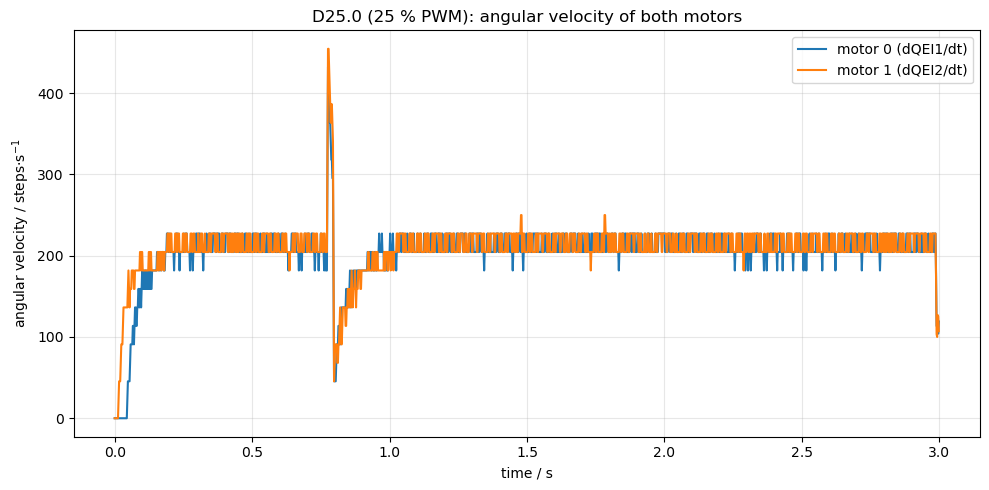

In [67]:
plot_velocity(dfs["D25"], "D25.0 (25 % PWM): angular velocity of both motors")
plt.show()

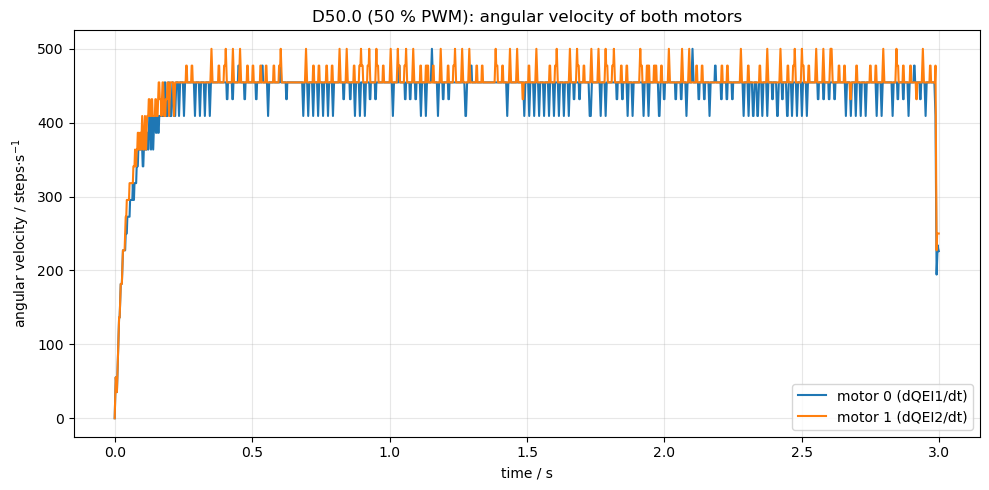

In [68]:
plot_velocity(dfs["D50"], "D50.0 (50 % PWM): angular velocity of both motors")
plt.show()

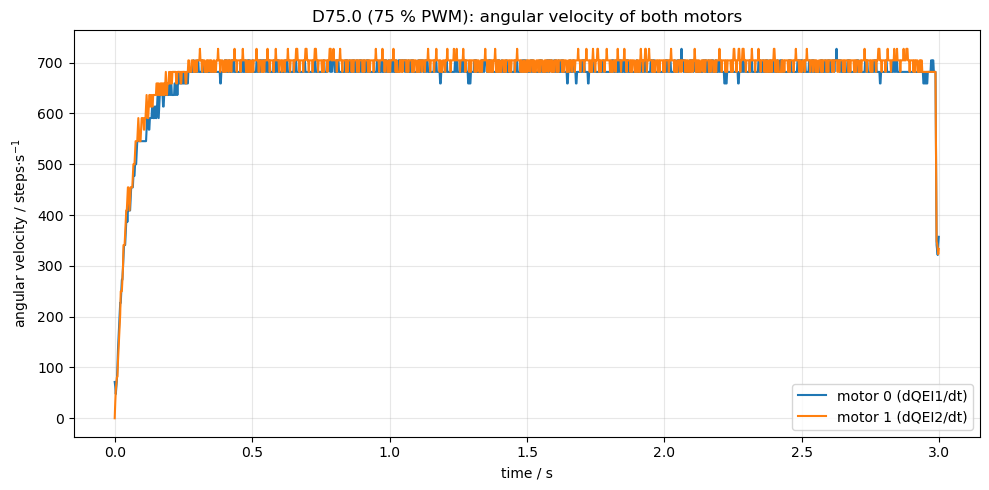

In [69]:
plot_velocity(dfs["D75"], "D75.0 (75 % PWM): angular velocity of both motors")
plt.show()

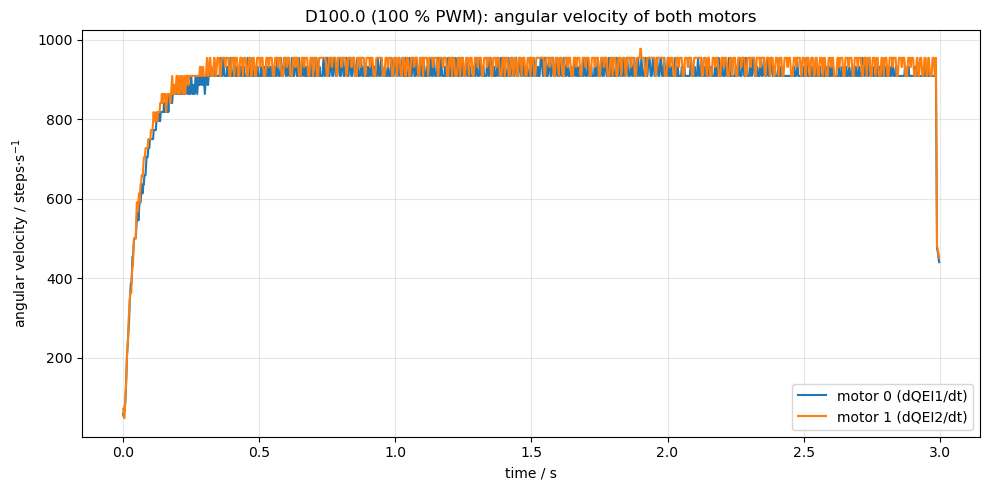

In [70]:
plot_velocity(dfs["D100"], "D100.0 (100 % PWM): angular velocity of both motors")
plt.show()

### second derivative of position plotted as angular acceleration of motors over time

### third derivative of position plotted as motor jerk over time

### differential-drive kinematics --- speed plotted as distance traveled over time (assuming no slip)

### Plots for report 
1) QEI position of motor 0 and motor 1 on the same time axis, together with the difference between the motor--motor1-speed pair colored, in one figure for all four main drive conditions (motor 0 should always be a dashed line and motor 1 should always be a solid line, with the same color for the same drive condition, and the difference(area) should colored in the same color but with higher opacity)

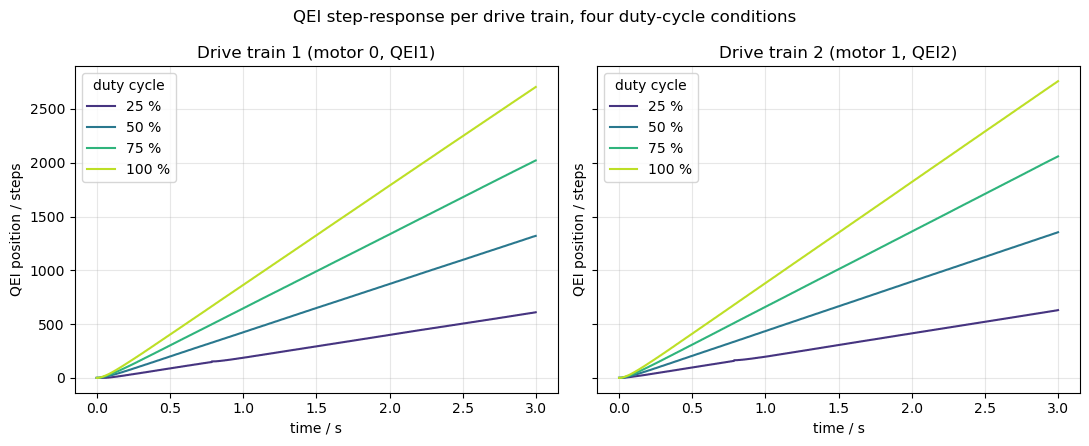

In [75]:
FIG_DIR = pl.Path("../01_RTP-Ausarbeitung/figure")
FIG_DIR.mkdir(parents=True, exist_ok=True)

DRIVES = [("D25", "25 %"), ("D50", "50 %"), ("D75", "75 %"), ("D100", "100 %")]
DRIVE_COLORS = plt.cm.viridis([0.15, 0.4, 0.65, 0.9])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for (key, label), color in zip(DRIVES, DRIVE_COLORS):
    axes[0].plot(dfs[key]["t/s"], dfs[key]["QEI1/steps"], label=label, color=color)
    axes[1].plot(dfs[key]["t/s"], dfs[key]["QEI2/steps"], label=label, color=color)
axes[0].set_title("Drive train 1 (motor 0, QEI1)")
axes[1].set_title("Drive train 2 (motor 1, QEI2)")
for ax in axes:
    ax.set_xlabel("time / s")
    ax.set_ylabel("QEI position / steps")
    ax.grid(True, alpha=0.3)
    ax.legend(title="duty cycle", loc="upper left")
fig.suptitle("QEI step-response per drive train, four duty-cycle conditions")
fig.tight_layout()

fig.savefig(FIG_DIR / "drive-position-comparison.pdf", bbox_inches="tight")
#fig.savefig(FIG_DIR / "drive-position-comparison.png", dpi=200, bbox_inches="tight")
plt.show()

### Plots for report 
1.2) QEI position of motor 0 and motor 1 on the same plot and time axis, together with the difference between the motor--motor1-speed pair colored, in one figure for all four main drive conditions (motor 0 should always be a dashed line and motor 1 should always be a solid line, with the same color for the same drive condition, and the difference(area) should colored in the same color but with higher opacity)

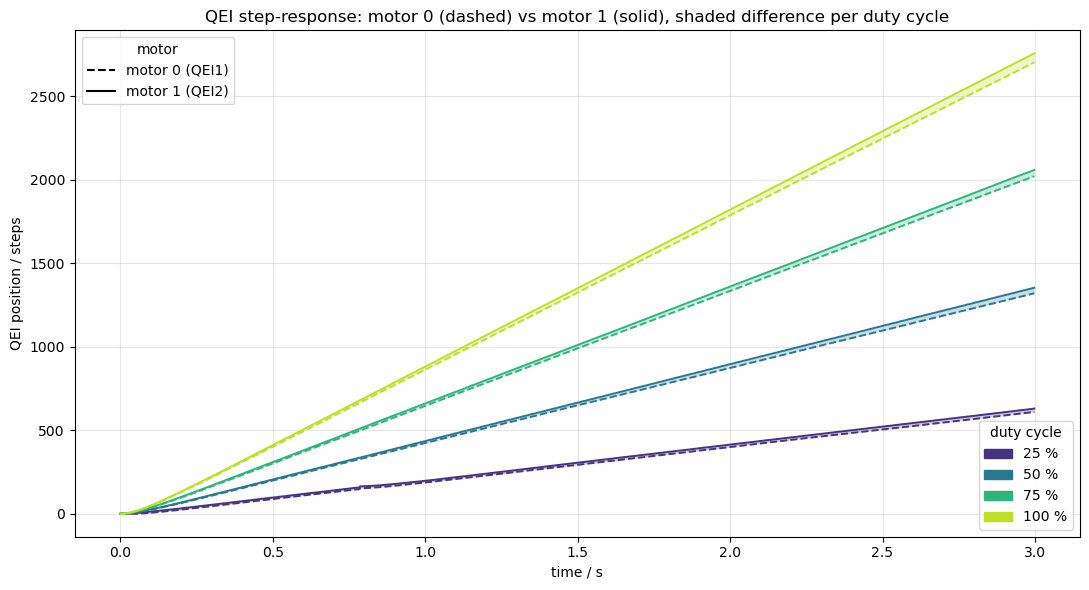

In [72]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(11, 6))

drive_handles = []
for (key, label), color in zip(DRIVES, DRIVE_COLORS):
    df = dfs[key]
    t = df["t/s"]
    q1 = df["QEI1/steps"]
    q2 = df["QEI2/steps"]
    ax.fill_between(t, q1, q2, color=color, alpha=0.25, linewidth=0)
    ax.plot(t, q1, color=color, linestyle="--", linewidth=1.4)
    ax.plot(t, q2, color=color, linestyle="-",  linewidth=1.4)
    drive_handles.append(Patch(facecolor=color, edgecolor=color, label=label))

style_handles = [
    Line2D([0], [0], color="black", linestyle="--", label="motor 0 (QEI1)"),
    Line2D([0], [0], color="black", linestyle="-",  label="motor 1 (QEI2)"),
]

ax.set_xlabel("time / s")
ax.set_ylabel("QEI position / steps")
ax.set_title("QEI step-response: motor 0 (dashed) vs motor 1 (solid), shaded difference per duty cycle")
ax.grid(True, alpha=0.3)

leg1 = ax.legend(handles=drive_handles, title="duty cycle", loc="lower right")
ax.add_artist(leg1)
ax.legend(handles=style_handles, title="motor", loc="upper left")

fig.tight_layout()
fig.savefig(FIG_DIR / "drive-position-overlap.pdf", bbox_inches="tight")
#fig.savefig(FIG_DIR / "drive-position-overlap.png", dpi=200, bbox_inches="tight")
plt.show()

### Plots for report
2) angular velocity of motor 0 and motor 1 

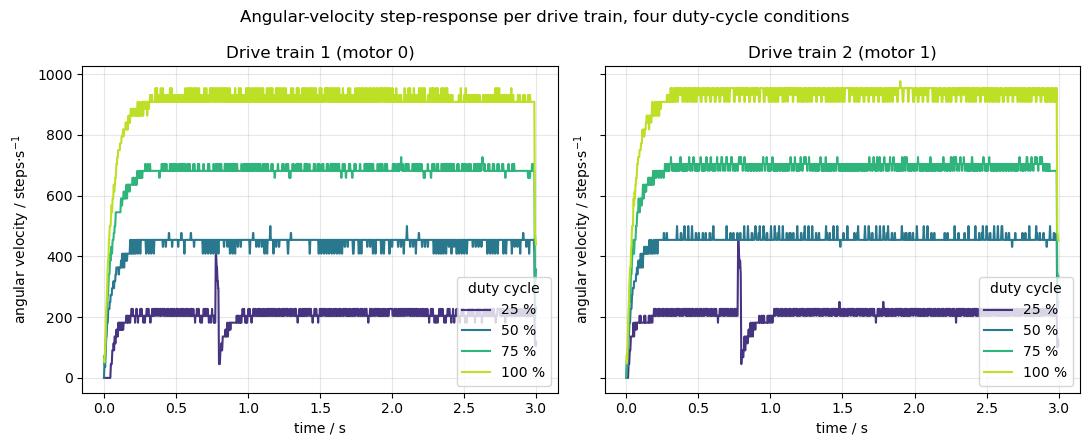

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for (key, label), color in zip(DRIVES, DRIVE_COLORS):
    df = dfs[key]
    axes[0].plot(df["t/s"], angular_velocity(df["QEI1/steps"], df["t/s"]),
                 label=label, color=color)
    axes[1].plot(df["t/s"], angular_velocity(df["QEI2/steps"], df["t/s"]),
                 label=label, color=color)
axes[0].set_title("Drive train 1 (motor 0)")
axes[1].set_title("Drive train 2 (motor 1)")
for ax in axes:
    ax.set_xlabel("time / s")
    ax.set_ylabel(r"angular velocity / steps$\cdot$s$^{-1}$")
    ax.grid(True, alpha=0.3)
    ax.legend(title="duty cycle", loc="lower right")
fig.suptitle("Angular-velocity step-response per drive train, four duty-cycle conditions")
fig.tight_layout()

fig.savefig(FIG_DIR / "drive-velocity-comparison.pdf", bbox_inches="tight")
#fig.savefig(FIG_DIR / "drive-velocity-comparison.png", dpi=200, bbox_inches="tight")
plt.show()

### Plots for report
3) QEI moving up and down plot from trial 5 (opposite direction) and showing that QEI output shows the motor spinning in the opposite direction if motor moves in the opposite direction\\
and the Angular-velocity of both motors 
motor0 d25.0 and motor1 d-25.0
all in one plot with a  `Left red`, `right green`. and the derivative in a lighter color of the same color as the position plot. 
